In [25]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Compare PPP values for ESM4 and ESM2M
- [ ] Global average PPP
- [ ] time horizon, plus difference

In [26]:
import xarray as xr
import esm4ppe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import matplotlib as mpl
from functions import *
import xesmf
from dask.diagnostics import ProgressBar

## Load data

In [27]:
basedir = '/projects/SOCCOM/graemem/projects/esm4_ppe'
# load esm2m
localdir = '/data/processed/esm2m/verify.metric-ppp'
ds_esm2m = xr.open_mfdataset('/'.join([basedir,localdir,'ocean.*.nc']))
# load esm4
ds_esm4 = esm4ppe.open_verify('ocean','monthly','ppp',groupby='month').sel(month=1).squeeze()
# load esm4 static
static = esm4ppe.open_static('intpp','monthly')

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [28]:
names = {'esm4':{'intpp':'intpp','tos':'tos','MLD_003':'MLD_003','geolat':'geolat','geolon':'geolon','areacello':'areacello'},
         'esm2m':{'intpp':'NPP','tos':'sst','MLD_003':'mld','geolat':'geolat_t','geolon':'geolon_t','areacello':'area_t'}}
thresholds = {'esm4':0.235559205,
              'esm2m':0.183}
colors = {'esm4':'tab:blue',
          'esm2m':'tab:orange'}
linestyles = {'esm2m':':',
              'esm4':'-'}
maskers = {'esm2m':'.',
           'esm4':'s'}
colors_v = {'intpp':'tab:green',
            'tos':'tab:blue',
            'MLD_003':'tab:orange'}

## Interpolate esm2m onto esm4

In [29]:
ds_esm2m_n = ds_esm2m.rename({'geolon_t':'lon','geolat_t':'lat','xt_ocean':'xh','yt_ocean':'yh'})
static_esm4 = static.rename({'geolon':'lon','geolat':'lat'})

In [30]:
regrid_2m24 = xesmf.Regridder(ds_esm2m_n,static_esm4,periodic=True,method='bilinear')

In [31]:
ds_esm2m_r = regrid_2m24(ds_esm2m_n)
ds_esm2m_r

<xarray.Dataset>
Dimensions:  (lead: 120, yh: 576, xh: 720)
Coordinates:
  * lead     (lead) int64 1 2 3 4 5 6 7 8 9 ... 113 114 115 116 117 118 119 120
  * xh       (xh) float64 -299.8 -299.2 -298.8 -298.2 ... 58.75 59.25 59.75
  * yh       (yh) float64 -77.91 -77.72 -77.54 -77.36 ... 89.47 89.68 89.89
Data variables:
    NPP      (lead, yh, xh) float32 dask.array<chunksize=(120, 200, 360), meta=np.ndarray>
    mld      (lead, yh, xh) float32 dask.array<chunksize=(120, 200, 360), meta=np.ndarray>
    sst      (lead, yh, xh) float32 dask.array<chunksize=(120, 200, 360), meta=np.ndarray>
Attributes:
    regrid_method:  bilinear

In [32]:
ds_esm4

<xarray.Dataset>
Dimensions:    (lead: 120, xh: 720, yh: 576)
Coordinates:
  * lead       (lead) int64 1 2 3 4 5 6 7 8 ... 113 114 115 116 117 118 119 120
  * xh         (xh) float64 -299.8 -299.2 -298.8 -298.2 ... 58.75 59.25 59.75
  * yh         (yh) float64 -77.91 -77.72 -77.54 -77.36 ... 89.47 89.68 89.89
    month      int64 1
Data variables:
    MLD_003    (lead, yh, xh) float32 dask.array<chunksize=(120, 576, 720), meta=np.ndarray>
    intpp      (lead, yh, xh) float32 dask.array<chunksize=(120, 576, 720), meta=np.ndarray>
    intppdiat  (lead, yh, xh) float32 dask.array<chunksize=(120, 576, 720), meta=np.ndarray>
    intppdiaz  (lead, yh, xh) float32 dask.array<chunksize=(120, 576, 720), meta=np.ndarray>
    intppmisc  (lead, yh, xh) float32 dask.array<chunksize=(120, 576, 720), meta=np.ndarray>
    intpppico  (lead, yh, xh) float32 dask.array<chunksize=(120, 576, 720), meta=np.ndarray>
    no3os      (lead, yh, xh) float32 dask.array<chunksize=(120, 576, 720), meta=np.ndarray>
    po4os      (lead, yh, xh) float32 dask.array<chunksize=(120, 576, 720), meta=np.ndarray>
    tos        (lead, yh, xh) float32 dask.array<chunksize=(120, 576, 720), meta=np.ndarray>

## Calculate time horizon

In [33]:
smooth = 12
variables = ['intpp','tos','MLD_003']
th_esm2m = xr.Dataset()
th_esm4 = xr.Dataset()
for variable in variables:
    # esm2m
    tmp = ds_esm2m_r[names['esm2m'][variable]]
    th_esm2m[variable] = calc_timehorizon(tmp,thresholds['esm2m'],dim='lead',smooth=smooth)
    # esm4
    tmp = ds_esm4[names['esm4'][variable]]
    th_esm4[variable] = calc_timehorizon(tmp,thresholds['esm4'],dim='lead',smooth=smooth)

In [34]:
with ProgressBar():
    th_esm2m = th_esm2m.compute()
    th_esm4 = th_esm4.compute()

[########################################] | 100% Completed | 12.92 s
[########################################] | 100% Completed | 8.40 sms


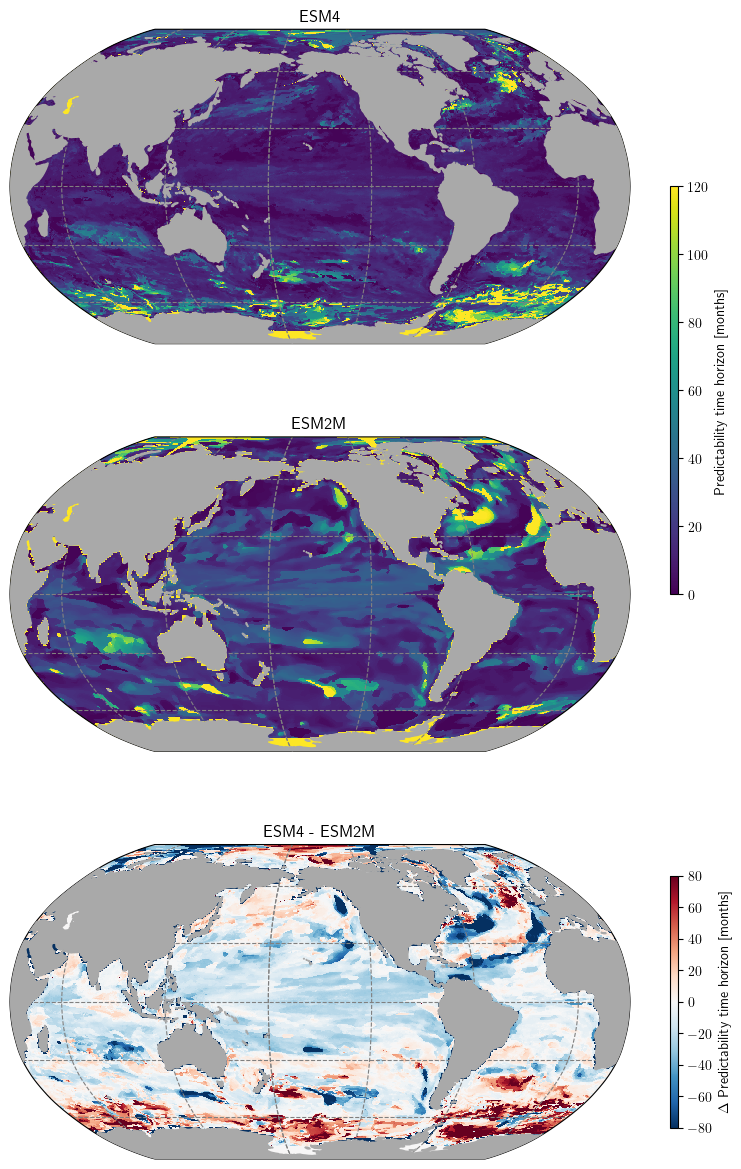

In [38]:
variable = 'MLD_003'
kwargs_th = {'vmin':0,'vmax':120}
kwargs_diff = {'vmin':-80,'vmax':80,'cmap':'RdBu_r'}

fig,ax = plt.subplots(figsize=(8,15),
                      nrows=3,
                      subplot_kw={'projection':ccrs.Robinson(central_longitude=-150)})

X,Y = static['geolon'],static['geolat']

axnow = ax[0]
Z = th_esm4[variable]
im = axnow.pcolormesh(X,Y,Z,transform=ccrs.PlateCarree(),**kwargs_th)
axnow.gridlines(color='gray',linestyle='dashed')
axnow.add_feature(cfeature.LAND,color='darkgrey',zorder=10)
axnow.set_title('ESM4')

bbox = axnow.get_position()
(left,bottom,width,height) = bbox.bounds
midway = bottom+height/2

axnow = ax[1]
Z = th_esm2m[variable]
im = axnow.pcolormesh(X,Y,Z,transform=ccrs.PlateCarree(),**kwargs_th)
axnow.gridlines(color='gray',linestyle='dashed')
axnow.add_feature(cfeature.LAND,color='darkgrey',zorder=10)
axnow.set_title('ESM2M')

bbox = axnow.get_position()
(left,bottom,width,height) = bbox.bounds
height_cb = midway-(bottom+height/2)
position = [left+width+0.05,bottom+height/2,0.01,height_cb]
_,imcb = add_colorbar(fig,im,position,orientation='vertical')
imcb.set_label('Predictability time horizon [months]')
            
axnow = ax[2]
Z = th_esm4[variable] - th_esm2m[variable]
im = axnow.pcolormesh(X,Y,Z,transform=ccrs.PlateCarree(),**kwargs_diff)
axnow.gridlines(color='gray',linestyle='dashed')
axnow.add_feature(cfeature.LAND,color='darkgrey',zorder=10)
axnow.set_title('ESM4 - ESM2M')

bbox = axnow.get_position()
(left,bottom,width,height) = bbox.bounds
position = [left+width+0.05,bottom+height/10,0.01,0.8*height]
_,imcb = add_colorbar(fig,im,position,orientation='vertical')
imcb.set_label(r'$\Delta$ Predictability time horizon [months]')

save_fig(fig,'fig.esm4-esm2m-comparison_ppp.timehorizon.'+variable)

## Calculate and plot global mean value of PPP

In [12]:
masks = esm4ppe.get_masks('basin',static)
ds_esm4_rm = esm4ppe.open_verifyregionalmean('ocean','monthly','basin','ppp',groupby='month').sel(month=1)

[########################################] | 100% Completed | 6.44 sms


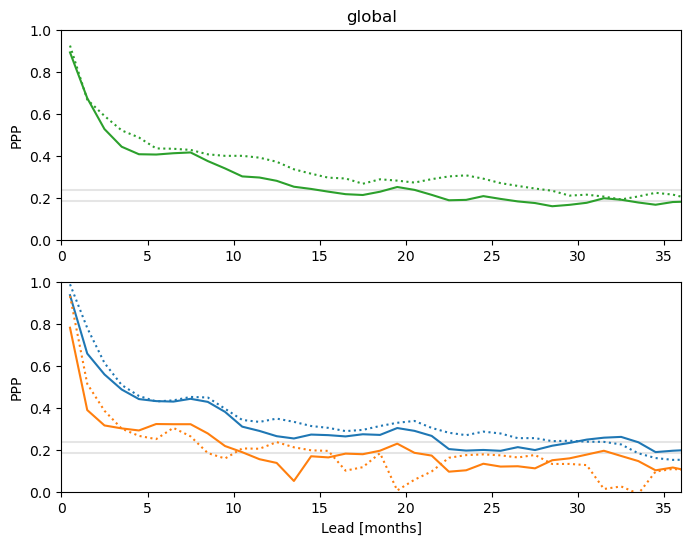

In [13]:
region='global'
ds_esm2m_rm = (ds_esm2m_r.where(masks[region])).weighted(static['areacello'].fillna(0)).mean(['xh','yh'])
with ProgressBar():
    ds_esm2m_rm = ds_esm2m_rm.compute()

variables = ['intpp','tos','MLD_003']
fig,ax = plt.subplots(figsize=(8,3*2),nrows=2)

for variable in variables:
    if variable=='intpp':
        axnow = ax[0]
        axnow.set_title(region)
    else:
        axnow = ax[1]
        axnow.set_xlabel('Lead [months]')
    da = ds_esm4_rm[names['esm4'][variable]].sel(region=region)
    axnow.plot(da['lead']-0.5,da,color=colors_v[variable],linestyle=linestyles['esm4'],label='esm4')

    da = ds_esm2m_rm[names['esm2m'][variable]]
    axnow.plot(da['lead']-0.5,da,color=colors_v[variable],linestyle=linestyles['esm2m'],label='esm2m')
    
    axnow.set_xlim([0,36])
    axnow.set_ylim([0,1])
    axnow.set_ylabel('PPP')
    
ax[0].axhline(thresholds['esm4'],color='k',linestyle='-',linewidth=1.5,alpha=0.1,zorder=0)
ax[0].axhline(thresholds['esm2m'],color='k',linestyle='-',linewidth=1.5,alpha=0.1,zorder=0)
ax[1].axhline(thresholds['esm4'],color='k',linestyle='-',linewidth=1.5,alpha=0.1,zorder=0)
ax[1].axhline(thresholds['esm2m'],color='k',linestyle='-',linewidth=1.5,alpha=0.1,zorder=0)

save_fig(fig,'fig.esm4-esm2m-comparison_ppp.ppp.'+region)

## Means in latitude bands

In [39]:
weights = static['areacello']
geolat = static['geolat']

firstdy = (static['yq'].values[0]-static['yh'].values[0])
lat_bins = np.append(static['yh'].values[0]-firstdy,static['yq'].values)

In [80]:
variable = 'intpp'
masknames_global = ['global','atlantic_global','pacific_global','indian_global']

da_esm2m = ds_esm2m_r[names['esm2m'][variable]]
da_esm4 = ds_esm4[names['esm4'][variable]]

lonmean_esm2m = xr.Dataset()
lonmean_esm4 = xr.Dataset()
for maskname in masknames_global:
    mask = masks[maskname]
    lonmean_esm2m[maskname] = calc_zonalmean(da_esm2m,mask,weights,geolat,lat_bins)
    lonmean_esm4[maskname] = calc_zonalmean(da_esm4,mask,weights,geolat,lat_bins)

In [81]:
with ProgressBar():
    lonmean_esm2m = lonmean_esm2m.compute()
    lonmean_esm4 = lonmean_esm4.compute()

[############                            ] | 31% Completed | 2.26 s ms

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


[########################################] | 100% Completed | 6.15 s
[########################################] | 100% Completed | 5.12 sms


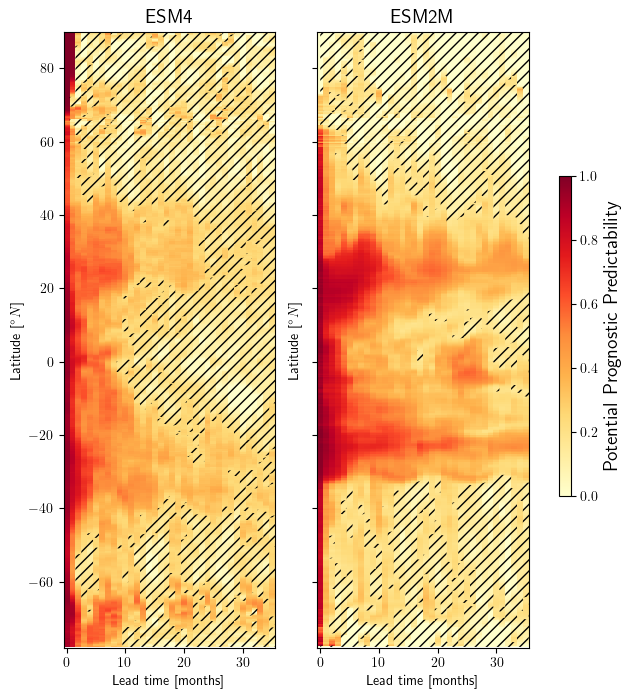

In [82]:
fig,ax = plt.subplots(figsize=(2*3,8),ncols=2)
region = 'pacific_global'

axnow = ax[0]
da = lonmean_esm4[region]
axnow,im = draw_zonalmeans(axnow,da,threshold=thresholds['esm4'],cmap='YlOrRd',vmin=0,vmax=1);
axnow.set_title('ESM4',fontsize=14)

axnow = ax[1]
da = lonmean_esm2m[region]
axnow,im = draw_zonalmeans(axnow,da,threshold=thresholds['esm2m'],cmap='YlOrRd',vmin=0,vmax=1);
axnow.set_title('ESM2M',fontsize=14)
axnow.set_yticklabels([])

_,imcb = add_colorbar(fig,im,[0.95,0.3,0.02,0.4],orientation='vertical')
imcb.set_label('Potential Prognostic Predictability',fontsize=14)

save_fig(fig,'fig.esm4-esm2m-comparison_ppp.lonmean.'+variable+'.'+region)

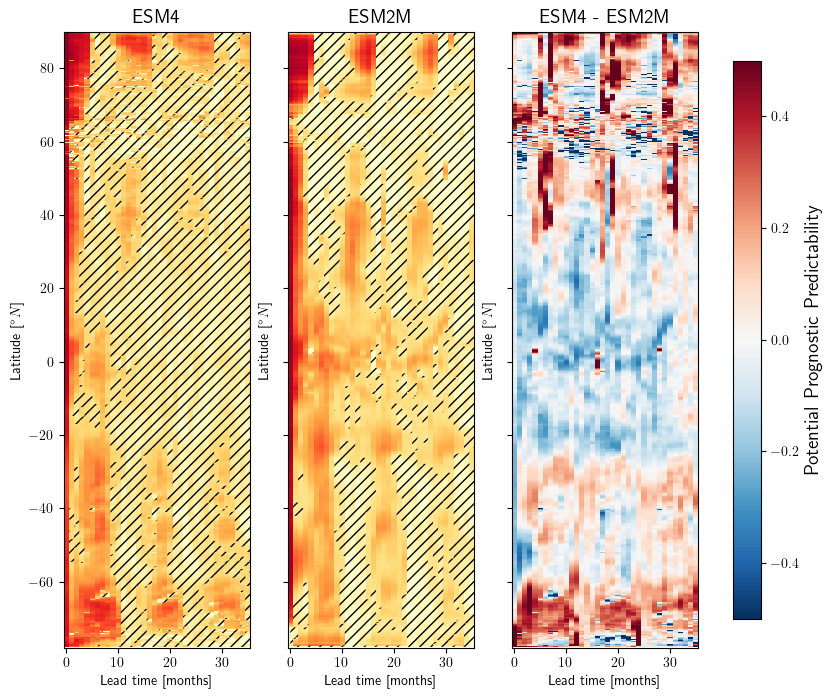

In [53]:
fig,ax = plt.subplots(figsize=(3*3,8),ncols=3)
region = 'pacific_global'

axnow = ax[0]
da = lonmean_esm4[region]
axnow,im = draw_zonalmeans(axnow,da,threshold=thresholds['esm4'],cmap='YlOrRd',vmin=0,vmax=1);
axnow.set_title('ESM4',fontsize=14)

axnow = ax[1]
da = lonmean_esm2m[region]
axnow,im = draw_zonalmeans(axnow,da,threshold=thresholds['esm2m'],cmap='YlOrRd',vmin=0,vmax=1);
axnow.set_title('ESM2M',fontsize=14)
axnow.set_yticklabels([])

axnow = ax[2]
da = lonmean_esm4[region] - lonmean_esm2m[region]
axnow,im = draw_zonalmeans(axnow,da,cmap='RdBu_r',vmin=-0.5,vmax=0.5);
axnow.set_title('ESM4 - ESM2M',fontsize=14)
axnow.set_yticklabels([]);

# cb = fig.colorbar(im,ax=ax,orientation='vertical',pad=0.05,fraction=0.04)
# cb.set_label('Potential Prognostic Predictability',fontsize=14)

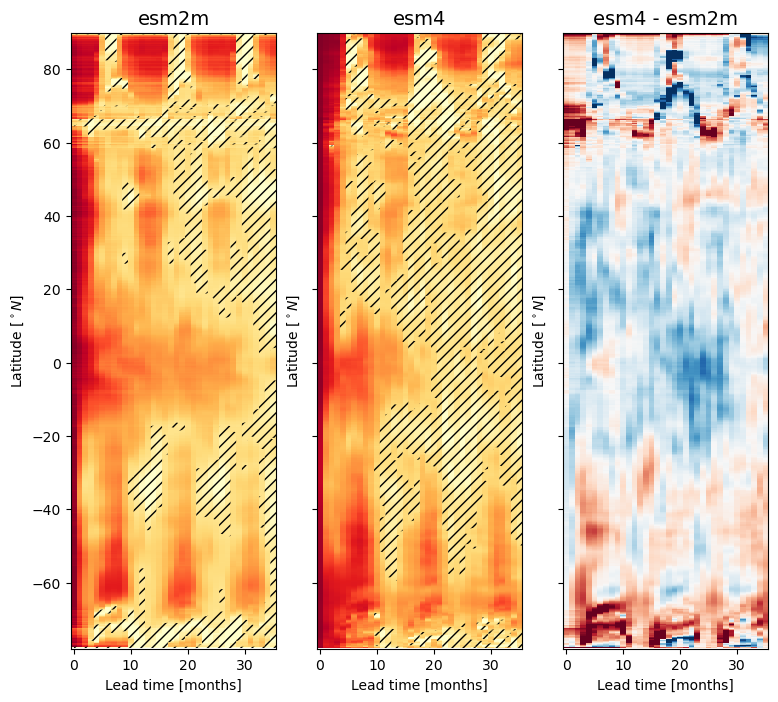

In [18]:
fig,ax = plt.subplots(figsize=(3*3,8),ncols=3)
region = 'pacific_global'

axnow = ax[0]
da = lonmean_esm2m[region]
axnow,im = draw_zonalmeans(axnow,da,threshold=thresholds['esm2m'],cmap='YlOrRd',vmin=0,vmax=1);
axnow.set_title('esm2m',fontsize=14)

axnow = ax[1]
da = lonmean_esm4[region]
axnow,im = draw_zonalmeans(axnow,da,threshold=thresholds['esm4'],cmap='YlOrRd',vmin=0,vmax=1);
axnow.set_title('esm4',fontsize=14)
axnow.set_yticklabels([])

axnow = ax[2]
da = lonmean_esm4[region] - lonmean_esm2m[region]
axnow,im = draw_zonalmeans(axnow,da,cmap='RdBu_r',vmin=-0.5,vmax=0.5);
axnow.set_title('esm4 - esm2m',fontsize=14)
axnow.set_yticklabels([]);

# cb = fig.colorbar(im,ax=ax,orientation='vertical',pad=0.05,fraction=0.04)
# cb.set_label('Potential Prognostic Predictability',fontsize=14)